#### Import libraries

In [10]:
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from silx.io.dictdump import h5todict

#### Solution

In [11]:
sol = h5todict(h5file='./physics/solution.hdf5')

In [12]:
# pbox = pd.read_csv("./ref_sol.dat", skiprows=2, header=None, delimiter="  ", engine='python')
# pbox.columns = ["t", "X_O"] + [f"X_O{i+1}" for i in range(3)] + ["T", "rho", "p", "n", "E"]
# Xi = ["X_O"] + [f"X_O{i+1}" for i in range(3)]

#### Time grid

In [13]:
t = sol['t']
nt = len(t)

#### Species evolution

In [14]:
def plot_species(
    x,
    y,
    xref=None,
    yref=None,
    labels=[r'$t$ [s]', r'$X$'],
    scales=['log', 'log'],
    names=None
):
    # Initialize figures
    fig = plt.figure()
    ax = fig.add_subplot()
    # x axis
    xlim = [np.amin(x), np.amax(x)]
    ax.set_xlim(xlim)
    ax.set_xlabel(labels[0])
    ax.set_xscale(scales[0])
    # y axis
    ax.set_ylabel(labels[1])
    ax.set_yscale(scales[1])
    # Plotting
    ax.plot(x, y, lw=1.0, label=names)
    if (xref is not None):
        ax.plot(xref, yref, lw=1.0, ls='--')
    plt.legend()
    plt.show()
    plt.close()

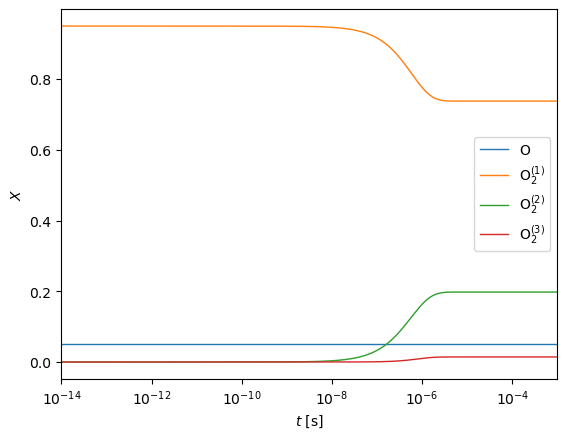

In [15]:
X = np.hstack([sol['X_O'],sol['X_O2']])
plot_species(
    t[1:],
    X[1:],
    # xref=pbox["t"].to_numpy()[1:],
    # yref=pbox[Xi].to_numpy()[1:],
    labels=[r'$t$ [s]', r'$X$'],
    scales=['log', 'linear'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(X.shape[1]-1)]
)

#### Mixture variables

In [16]:
def plot_var(
    x,
    y,
    xref=None,
    yref=None,
    labels=[r'$t$ [s]', r'$p$ [Pa]'],
    scales=['log', 'linear']
):
    # Initialize figures
    fig = plt.figure()
    ax = fig.add_subplot()
    # x axis
    xlim = [np.amin(x), np.amax(x)]
    ax.set_xlim(xlim)
    ax.set_xlabel(labels[0])
    ax.set_xscale(scales[0])
    # y axis
    ax.set_ylabel(labels[1])
    ax.set_yscale(scales[1])
    # Plotting
    ax.plot(x, y, lw=1.0)
    if (xref is not None):
        ax.plot(xref, yref, lw=1.0)
    plt.show()
    plt.close()

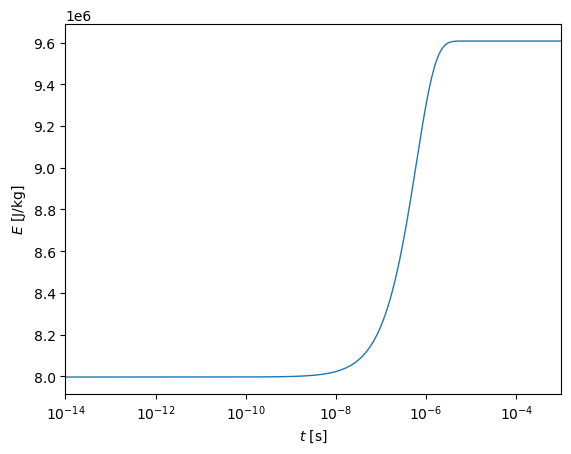

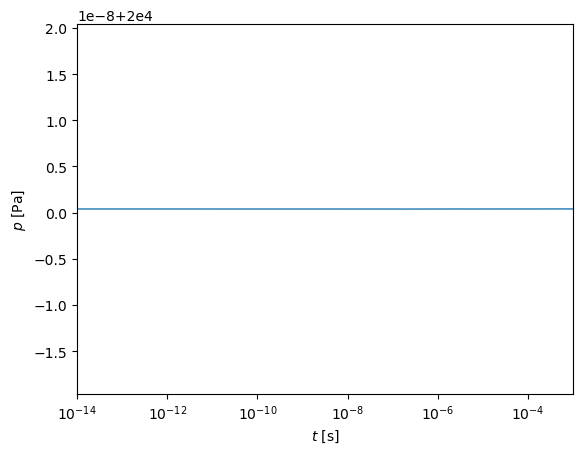

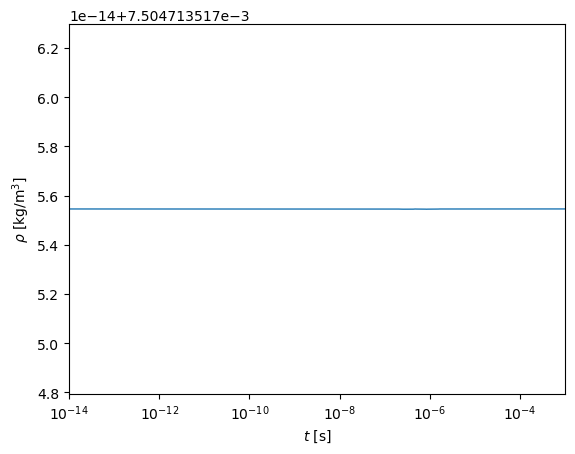

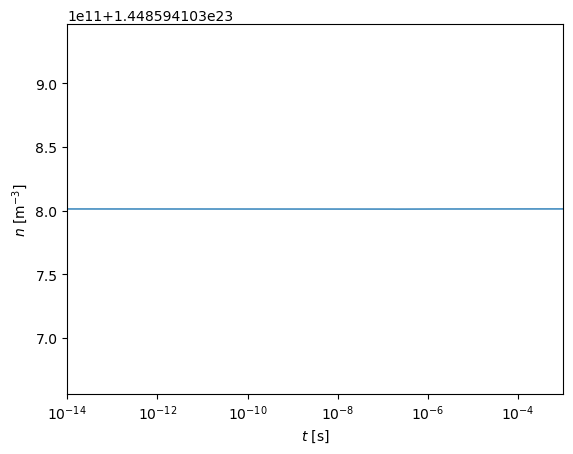

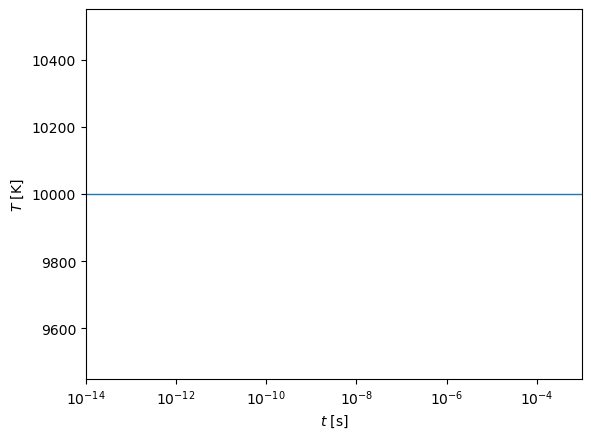

In [17]:
labels = {
    'E': r'$E$ [J/kg]',
    'p': r'$p$ [Pa]',
    'rho': r'$\rho$ [kg/m$^{3}$]',
    'n': r'$n$ [m$^{-3}$]',
    'T': r'$T$ [K]'
}
for k in ('E', 'p', 'rho', 'n', 'T'):
    plot_var(
        t[1:],
        sol[k][1:],
        # xref=pbox["t"],
        # yref=pbox[k],
        labels=[r'$t$ [s]', labels[k]]
    )